# Titanic Survival Prediction: End-to-End Machine Learning Pipeline

Welcome to this comprehensive machine learning notebook! The goal of this project is to build a predictive model that answers the question: *"what sorts of people were more likely to survive?"* using passenger data (ie. name, age, gender, socio-economic class, etc.).

### Pipeline Overview:
1. **Data Loading & Inspection**: Import datasets and combine them for consistent preprocessing.
2. **Missing Value Imputation**: Handle missing data for Age, Fare, Embarked, and Cabin.
3. **Feature Engineering**: Extract titles, family sizes, ticket groupings, and bin numerical features.
4. **Encoding**: Convert categorical features into numeric formats.
5. **Model Training & Evaluation**: Train a Random Forest classifier and evaluate its performance.
6. **Submission Generation**: Format predictions into a Kaggle-ready CSV file.

### **1. Loading the Datasets**
we load the essential data science libraries and import our training and testing datasets from the Kaggle directory.

In [1]:
# Import essential data science and manipulation libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load training and testing datasets from the local data directory
train_pd = pd.read_csv("data/train.csv")
test_pd = pd.read_csv("data/test.csv")

# Preview the first few rows of the training dataset using .head() for a cleaner output
display(train_pd.head())

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


### **2. Combining Train & Test Sets**
We separate the target variable (`Survived`) from the training data and save the passenger IDs of both sets for later use. We then combine the train and test sets temporarily, which ensures that any feature engineering or categorical encoding is applied uniformly across both.

In [2]:
# Extract the target variable ('Survived') from the training dataset
survived = train_pd['Survived']

# Drop 'Survived' from train_pd so columns match the test set for concatenation
train_pd = train_pd.drop(['Survived'], axis=1)

# Save passenger IDs for later submission use, then combine train and test sets
train_idx = train_pd['PassengerId']
test_idx = test_pd['PassengerId']

combined_pd = pd.concat([train_pd, test_pd]).reset_index(drop=True)

# Preview the combined dataset
display(combined_pd.head())

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


### **3. Missing Values Analysis**
Before imputing missing data, we inspect our combined dataset to identify exactly how many null values exist across each feature column.

In [3]:
# Check and display the total count of missing (null) values per column
print("NULL VALUES:")
print(combined_pd.isnull().sum())

NULL VALUES:
PassengerId       0
Pclass            0
Name              0
Sex               0
Age             263
SibSp             0
Parch             0
Ticket            0
Fare              1
Cabin          1014
Embarked          2
dtype: int64


### **4. Age Data Analysis & Imputation**
We notice that passenger age correlates strongly with passenger class (e.g., first-class passengers tend to be older), and also differs between men and women within each class. Instead of filling missing ages with the overall global median, we impute them using the median age of passengers with the same class (`Pclass`) **and** sex (`Sex`).

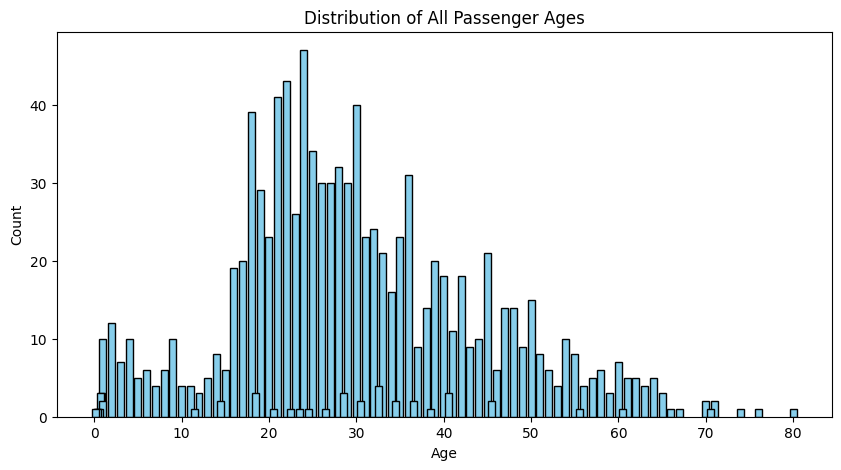

In [4]:
# Visualize the distribution of ages across the dataset
age_counts = combined_pd['Age'].value_counts()
ages = age_counts.index.values

plt.figure(figsize=(10, 5))
plt.bar(ages, age_counts, color='skyblue', edgecolor='black')
plt.title("Distribution of All Passenger Ages")
plt.xlabel("Age")
plt.ylabel("Count")
plt.show()

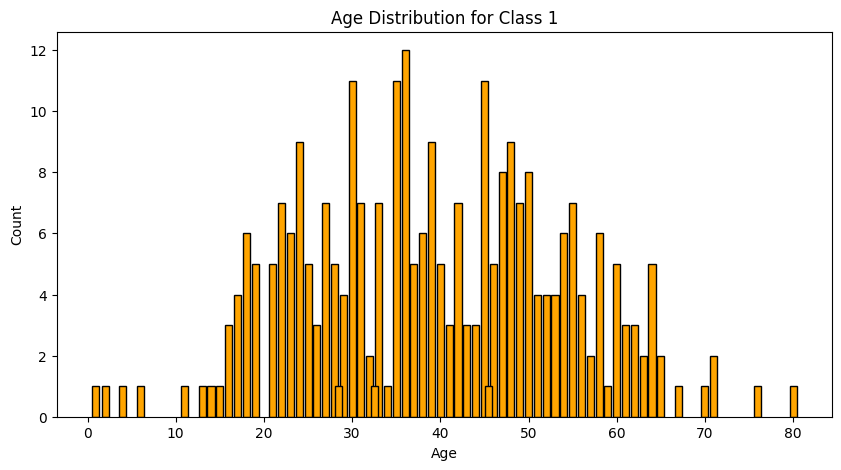

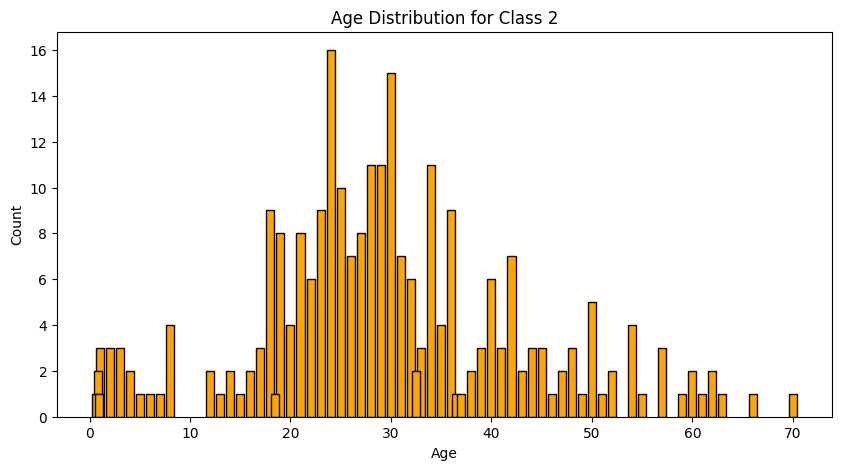

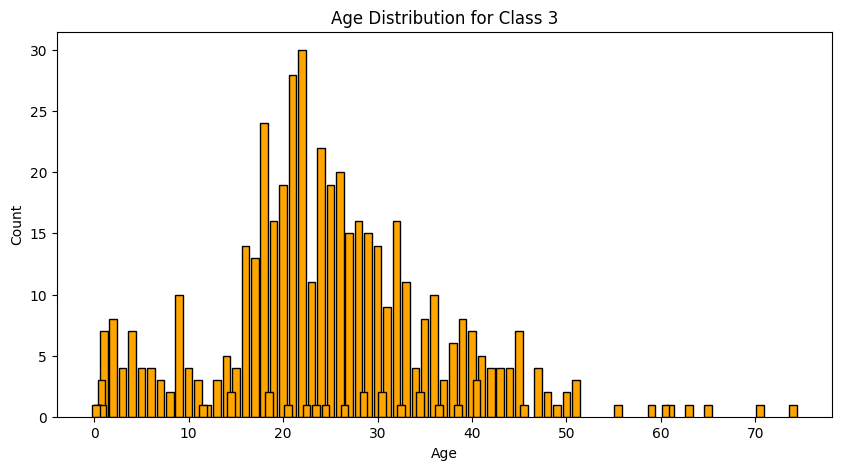

Median Ages by Class and Sex:
Pclass  Sex   
1       female    36.0
        male      42.0
2       female    28.0
        male      29.5
3       female    22.0
        male      25.0
Name: Age, dtype: float64


In [5]:
# Visualize age distributions broken down by Passenger Class
class_age = combined_pd[['Pclass', 'Age']]

for pclass in range(1, 4):
    plt.figure(figsize=(10, 5))
    plt.title(f'Age Distribution for Class {pclass}')
    class_data = class_age[class_age['Pclass'] == pclass]['Age'].value_counts()
    plt.bar(class_data.index.values, class_data.values, color='orange', edgecolor='black')
    plt.xlabel("Age")
    plt.ylabel("Count")
    plt.show()

# Calculate the median age for each passenger class and sex
age_medians = combined_pd.groupby(['Pclass', 'Sex'])['Age'].median()
print("Median Ages by Class and Sex:")
print(age_medians)

# Fill each missing age with the median of passengers in the same class and sex
combined_pd['Age'] = combined_pd['Age'].fillna(
    combined_pd.groupby(['Pclass', 'Sex'])['Age'].transform('median')
)


### **5. Missing Fare Imputation**
We identify passengers with missing fare data and fill them using the median fare of similar passengers (those in the same passenger class and boarding port).

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
1043,1044,3,"Storey, Mr. Thomas",male,60.5,0,0,3701,NaN,NaN,S


Calculated Median Fare: 8.05


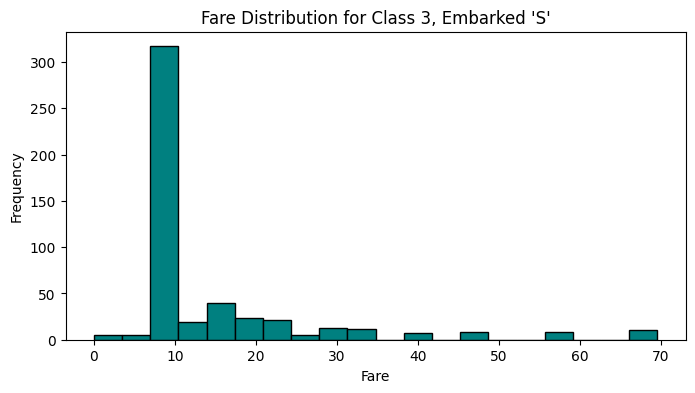

In [6]:
# Display the row with the missing Fare value
display(combined_pd[combined_pd['Fare'].isnull()])

# Find similar passengers (3rd class, embarked from 'S') and calculate their median fare
sim_fares = combined_pd[(combined_pd['Pclass'] == 3) & (combined_pd['Embarked'] == 'S')]['Fare']
print('Calculated Median Fare:', sim_fares.median())

# Plot the fare distribution for context
plt.figure(figsize=(8, 4))
plt.hist(sim_fares.dropna(), bins=20, color='teal', edgecolor='black')
plt.title("Fare Distribution for Class 3, Embarked 'S'")
plt.xlabel("Fare")
plt.ylabel("Frequency")
plt.show()

# Fill the missing Fare value with the calculated median
combined_pd['Fare'] = combined_pd['Fare'].fillna(sim_fares.median())

### **6. Missing Embarked Imputation**
We check passengers with missing port of embarkation (`Embarked`) values and deduce their location based on class and ticket fare.

In [7]:
# Display passengers with missing Embarked values
display(combined_pd[combined_pd['Embarked'].isnull()])

# Analyze embarkation ports for first-class passengers who paid a similar fare (~80)
sim_emb = combined_pd[(combined_pd['Pclass'] == 1) & (combined_pd['Fare'] >= 75) & (combined_pd['Fare'] <= 85)]['Embarked']
print("Embarkation counts for similar fares:")
print(sim_emb.value_counts())

# Fill missing Embarked values with the most frequent port ('C')
combined_pd['Embarked'] = combined_pd['Embarked'].fillna('C')

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
61,62,1,"Icard, Miss. Amelie",female,38.0,0,0,113572,80.0,B28,NaN
829,830,1,"Stone, Mrs. George Nelson (Martha Evelyn)",female,62.0,0,0,113572,80.0,B28,NaN


Embarkation counts for similar fares:
Embarked
C    25
S    18
Name: count, dtype: int64


### **7. Cabin Feature Cleaning & Imputation**
Since a large majority of cabin data is missing, we fill missing values with a placeholder category `'M'` (for Missing). Then, we extract the first letter of each cabin to represent the ship deck.

In [8]:
# Fill missing Cabin values with 'M' (Missing)
combined_pd['Cabin'] = combined_pd['Cabin'].fillna('M')

# Extract the first letter of the cabin to represent the deck level
combined_pd['Cabin'] = combined_pd['Cabin'].str[0]
print("Cabin Deck Value Counts:")
print(combined_pd['Cabin'].value_counts())

# Replace the rare/unknown 'T' cabin with 'M'
rare_indices = np.where(combined_pd['Cabin'] == 'T')[0]
combined_pd.loc[rare_indices, 'Cabin'] = 'M'

# Verify updated cabin value counts
print("\nUpdated Cabin Deck Value Counts:")
print(combined_pd['Cabin'].value_counts())

Cabin Deck Value Counts:
Cabin
M    1014
C      94
B      65
D      46
E      41
A      22
F      21
G       5
T       1
Name: count, dtype: int64

Updated Cabin Deck Value Counts:
Cabin
M    1015
C      94
B      65
D      46
E      41
A      22
F      21
G       5
Name: count, dtype: int64


### **8. Dataset Verification & Unique Values**
We verify that no null values remain in the dataset and inspect unique value counts across all features.

In [9]:
# Verify that no missing values remain in the dataset
print("Remaining Null Values:")
print(combined_pd.isnull().sum())

# Check unique value counts for each feature
print("\nUnique Value Counts:")
print(combined_pd.nunique())

Remaining Null Values:
PassengerId    0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Cabin          0
Embarked       0
dtype: int64

Unique Value Counts:
PassengerId    1309
Pclass            3
Name           1307
Sex               2
Age              99
SibSp             7
Parch             8
Ticket          929
Fare            281
Cabin             8
Embarked          3
dtype: int64


### **9. Name Processing**
We parse passenger names into last name, title and first name. The title (e.g., Mr, Miss, Mrs, Master) is used as a predictive feature, since it captures both sex and approximate age.

In [10]:
# Extract titles and last names from the 'Name' column
names = combined_pd['Name']
last_names, titles, first_names = [], [], []

for name in names:
    if ', ' not in name:
        last_names.append('')
    else:
        last, remaining = name.split(', ', 1)
        last_names.append(last)
        name = remaining

    if '. ' not in name:
        titles.append('')
        first_names.append(name)
    else:
        title, first = name.split('. ', 1)
        titles.append(title)
        first_names.append(first)

# Convert lists to NumPy arrays
last_names = np.array(last_names)
titles = np.array(titles)
first_names = np.array(first_names)

# Inspect unique extracted titles and their counts
unique_titles, title_counts = np.unique(titles, return_counts=True)
print("Extracted Titles and Counts:")
for t, c in zip(unique_titles, title_counts):
    print(f"  {t}: {c}")

Extracted Titles and Counts:
  Capt: 1
  Col: 4
  Don: 1
  Dona: 1
  Dr: 8
  Jonkheer: 1
  Lady: 1
  Major: 2
  Master: 61
  Miss: 260
  Mlle: 2
  Mme: 1
  Mr: 757
  Mrs: 197
  Ms: 2
  Rev: 8
  Sir: 1
  the Countess: 1


### **10. Title Grouping**
To reduce cardinality and improve machine learning model stability, we group rare and similar titles together (e.g., military titles, nobility, and alternate forms of Miss/Mrs). `Master`, the title used for young boys, is kept as its own group because it is a strong survival signal.

In [11]:
# Group rare titles into broader categories
idx = np.where(np.isin(titles, ['Capt', 'Col', 'Major']))
titles[idx] = 'Military'

idx = np.where(np.isin(titles, ['Don', 'Dona', 'Jonkheer', 'Lady', 'Sir', 'the Countess']))
titles[idx] = 'Nobility'

idx = np.where(np.isin(titles, ['Miss', 'Ms', 'Mlle']))
titles[idx] = 'Ms'

idx = np.where(np.isin(titles, ['Mrs', 'Mme']))
titles[idx] = 'Mrs'

print(np.unique(titles, return_counts=True))

# Add the cleaned titles as a new column in the combined dataframe
combined_pd['Title'] = titles
display(combined_pd.head())

(array(['Dr', 'Master', 'Military', 'Mr', 'Mrs', 'Ms', 'Nobility', 'Rev'],
      dtype='<U12'), array([  8,  61,   7, 757, 198, 264,   6,   8]))


,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Title
0,1,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,M,S,Mr
1,2,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C,C,Mrs
2,3,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,M,S,Ms
3,4,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C,S,Mrs
4,5,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,M,S,Mr


### **11. Age Binning**
We convert continuous age values into categorical age brackets to help tree-based models identify non-linear survival patterns.

In [12]:
print(combined_pd['Age'].min(), combined_pd['Age'].max())

bins = [0, 10, 20, 30, 40, 50, 60, 70, 80]
combined_pd['Age_Bin'] = pd.cut(combined_pd['Age'], bins)

display(combined_pd.head())

0.17 80.0


,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Title,Age_Bin
0,1,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,M,S,Mr,"(20, 30]"
1,2,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C,C,Mrs,"(30, 40]"
2,3,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,M,S,Ms,"(20, 30]"
3,4,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C,S,Mrs,"(30, 40]"
4,5,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,M,S,Mr,"(30, 40]"


### **12. Ticket & Fare-per-Ticket Analysis**
Passengers sharing the same ticket often traveled together in groups, and the listed fare is the total for the whole ticket. We calculate how many passengers share each ticket and divide the fare by that count to get the fare per person. Finally, we group these values into fare brackets (`Fare_Bin`).

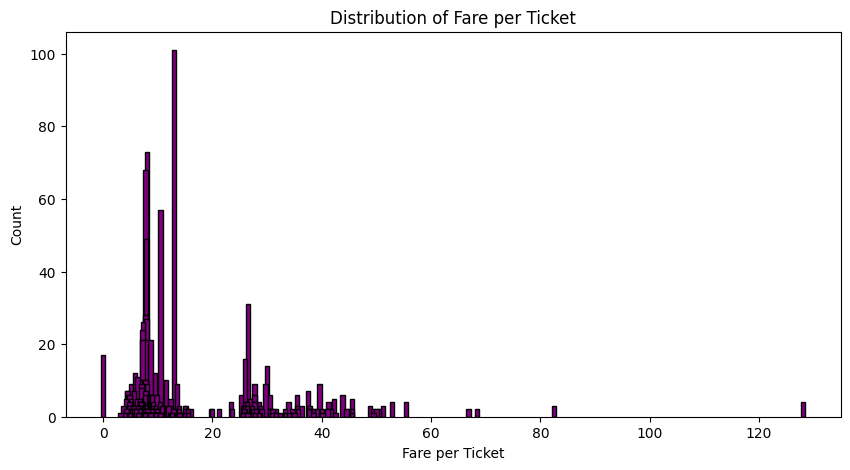

0.0 128.0823


,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Title,Age_Bin,tkt_count,Fare_per_Ticket,Fare_Bin
0,1,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,M,S,Mr,"(20, 30]",1,7.25000,"(-0.001, 20.0]"
1,2,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C,C,Mrs,"(30, 40]",2,35.64165,"(20.0, 40.0]"
2,3,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,M,S,Ms,"(20, 30]",1,7.92500,"(-0.001, 20.0]"
3,4,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C,S,Mrs,"(30, 40]",2,26.55000,"(20.0, 40.0]"
4,5,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,M,S,Mr,"(30, 40]",1,8.05000,"(-0.001, 20.0]"


In [13]:
# Count occurrences of each ticket to find group sizes
ticket_dict = dict(combined_pd['Ticket'].value_counts())
combined_pd['tkt_count'] = combined_pd['Ticket'].map(ticket_dict)

# Calculate fare per ticket
combined_pd['Fare_per_Ticket'] = combined_pd['Fare'] / combined_pd['tkt_count']

# Plot fare per ticket distribution with consistent sizing
plt.figure(figsize=(10, 5))
plt.bar(combined_pd['Fare_per_Ticket'].value_counts().index.values, combined_pd['Fare_per_Ticket'].value_counts(), color='purple', edgecolor='black')
plt.title("Distribution of Fare per Ticket")
plt.xlabel("Fare per Ticket")
plt.ylabel("Count")
plt.show()

print(combined_pd['Fare_per_Ticket'].min(), combined_pd['Fare_per_Ticket'].max())

bins = [0, 20, 40, 60, 80, 150]
combined_pd['Fare_Bin'] = pd.cut(combined_pd['Fare_per_Ticket'], bins, include_lowest=True)

display(combined_pd.head())

### **13. Family Size Feature Engineering**
We combine siblings/spouses (`SibSp`) and parents/children (`Parch`) plus the passenger themselves to determine total family size (`Num_Family`). We also group family size into three categories (`Family_Type`): **Alone** (1), **Small** (2–4) and **Large** (5+).

In [14]:
# Calculate total family size per passenger
combined_pd['Num_Family'] = combined_pd['SibSp'] + combined_pd['Parch'] + 1

# Group family size: alone (1), small (2-4), large (5+)
combined_pd['Family_Type'] = pd.cut(combined_pd['Num_Family'], [0, 1, 4, 11],
                                    labels=['Alone', 'Small', 'Large'])
display(combined_pd.head())

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Title,Age_Bin,tkt_count,Fare_per_Ticket,Fare_Bin,Num_Family,Family_Type
0,1,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,M,S,Mr,"(20, 30]",1,7.25000,"(-0.001, 20.0]",2,Small
1,2,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C,C,Mrs,"(30, 40]",2,35.64165,"(20.0, 40.0]",2,Small
2,3,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,M,S,Ms,"(20, 30]",1,7.92500,"(-0.001, 20.0]",1,Alone
3,4,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C,S,Mrs,"(30, 40]",2,26.55000,"(20.0, 40.0]",2,Small
4,5,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,M,S,Mr,"(30, 40]",1,8.05000,"(-0.001, 20.0]",1,Alone


### **14. Cleaning Up Unnecessary Columns**
Now that we have extracted all relevant features (Titles, Age Bins, Fare Bins, Family Size and Family Type), we drop the raw columns they were built from (`Name`, `Age`, `Ticket`, `Fare`, `SibSp`, `Parch`) along with the helper columns (`tkt_count`, `Fare_per_Ticket`) to prepare our final dataset for modeling.

In [15]:
# Drop raw columns that have been replaced by engineered features
combined_pd.drop(['Name', 'Age', 'Ticket', 'Fare', 'tkt_count', 'Fare_per_Ticket',
                  'SibSp', 'Parch'], axis=1, inplace=True)

# Preview the final prepared combined dataframe
display(combined_pd.head())

,PassengerId,Pclass,Sex,Cabin,Embarked,Title,Age_Bin,Fare_Bin,Num_Family,Family_Type
0,1,3,male,M,S,Mr,"(20, 30]","(-0.001, 20.0]",2,Small
1,2,1,female,C,C,Mrs,"(30, 40]","(20.0, 40.0]",2,Small
2,3,3,female,M,S,Ms,"(20, 30]","(-0.001, 20.0]",1,Alone
3,4,1,female,C,S,Mrs,"(30, 40]","(20.0, 40.0]",2,Small
4,5,3,male,M,S,Mr,"(30, 40]","(-0.001, 20.0]",1,Alone


### **15. Model & Metric Imports**
We import the necessary machine learning classifiers, cross-validation tools, and evaluation metrics from scikit-learn.

In [16]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, RandomizedSearchCV, GridSearchCV
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import LabelEncoder

### **16. Setting Index to PassengerId**
We assign `PassengerId` as the index frame to accurately keep track of individual rows.

In [17]:
# Set PassengerId as index
combined_pd.set_index('PassengerId', inplace=True)
display(combined_pd.head())

,Pclass,Sex,Cabin,Embarked,Title,Age_Bin,Fare_Bin,Num_Family,Family_Type
PassengerId,,,,,,,,,
1,3,male,M,S,Mr,"(20, 30]","(-0.001, 20.0]",2,Small
2,1,female,C,C,Mrs,"(30, 40]","(20.0, 40.0]",2,Small
3,3,female,M,S,Ms,"(20, 30]","(-0.001, 20.0]",1,Alone
4,1,female,C,S,Mrs,"(30, 40]","(20.0, 40.0]",2,Small
5,3,male,M,S,Mr,"(30, 40]","(-0.001, 20.0]",1,Alone


### **17. Label Encoding Categorical Features**
We convert categorical features into integers so models can ingest them. Only the text columns (`Sex`, `Cabin`, `Embarked`, `Title`) are label-encoded. The binned columns (`Age_Bin`, `Fare_Bin`, `Family_Type`) use their category codes, which preserves their natural order, and numeric columns keep their original values.

In [18]:
# Copy dataframe and encode categorical strings into numeric labels
label_enc = combined_pd.copy()

# Encode only real text columns, numeric columns keep their true values
for col in ['Sex', 'Cabin', 'Embarked', 'Title']:
    label_enc[col] = LabelEncoder().fit_transform(label_enc[col])

# Binned columns are categories already; .cat.codes keeps their correct order
for col in ['Age_Bin', 'Fare_Bin', 'Family_Type']:
    label_enc[col] = label_enc[col].cat.codes

display(label_enc)

,Pclass,Sex,Cabin,Embarked,Title,Age_Bin,Fare_Bin,Num_Family,Family_Type
PassengerId,,,,,,,,,
1,3,1,7,2,3,2,0,2,1
2,1,0,2,0,4,3,1,2,1
3,3,0,7,2,5,2,0,1,0
4,1,0,2,2,4,3,1,2,1
5,3,1,7,2,3,3,0,1,0
...,...,...,...,...,...,...,...,...,...
1305,3,1,7,2,3,2,0,1,0
1306,1,0,2,0,6,3,1,1,0
1307,3,1,7,2,3,3,0,1,0


### **18. One-Hot Encoding**
To prevent tree models from treating category labels with a false quantitative hierarchy (e.g., assuming $2 > 1$), we apply One-Hot Encoding via `pd.get_dummies` to nominal columns like `Sex`, `Embarked`, and `Title`.

In [19]:
# Create explicit binary indicator columns for nominal features
one_hot = label_enc.copy()

one_hot = pd.get_dummies(one_hot, columns=['Sex', 'Embarked', 'Title'])

display(one_hot)

,Pclass,Cabin,Age_Bin,Fare_Bin,Num_Family,Family_Type,Sex_0,Sex_1,Embarked_0,Embarked_1,Embarked_2,Title_0,Title_1,Title_2,Title_3,Title_4,Title_5,Title_6,Title_7
PassengerId,,,,,,,,,,,,,,,,,,,
1,3,7,2,0,2,1,False,True,False,False,True,False,False,False,True,False,False,False,False
2,1,2,3,1,2,1,True,False,True,False,False,False,False,False,False,True,False,False,False
3,3,7,2,0,1,0,True,False,False,False,True,False,False,False,False,False,True,False,False
4,1,2,3,1,2,1,True,False,False,False,True,False,False,False,False,True,False,False,False
5,3,7,3,0,1,0,False,True,False,False,True,False,False,False,True,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1305,3,7,2,0,1,0,False,True,False,False,True,False,False,False,True,False,False,False,False
1306,1,2,3,1,1,0,True,False,True,False,False,False,False,False,False,False,False,True,False
1307,3,7,3,0,1,0,False,True,False,False,True,False,False,False,True,False,False,False,False


### **19. Splitting and Scaling Data for Modeling**
We extract the training passengers from our processed dataset, scale their feature values to a 0–1 range with `MinMaxScaler`, and split them into an 80% training set and a 20% validation set used to measure model accuracy.

In [20]:
# Slice training rows back out and align target labels
X = one_hot.loc[train_idx].values
y = survived.values

# Scale feature values between 0 and 1
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

# Split into local training and validation partitions
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=.2, random_state=0)
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(712, 19) (179, 19) (712,) (179,)


### **20. Baseline Model Training**
Quickly fitting a default Random Forest classifier to check base performance metrics.

In [21]:
# Instantiate and evaluate a baseline Random Forest model
clf = RandomForestClassifier(random_state=0)
clf.fit(X_train, y_train).score(X_test, y_test)

0.8268156424581006

### **21. Hyperparameter Tuning with RandomizedSearchCV**
We search 100 random combinations from a wide range of hyperparameters, using 5-fold cross-validation, to locate a strong starting configuration.

In [22]:
# Define hyperparameter grid spaces for random search
params = {'criterion': ['gini', 'entropy'],
          'n_estimators': [100, 200, 300, 500],
          'max_depth': [3, 4, 5, 6, 7, 8, 10, None],
          'min_samples_split': np.arange(2, 30),
          'min_samples_leaf': [1, 2, 3, 5],
          'max_features': ['sqrt', 'log2'],
          'max_samples': np.linspace(0.5, 0.9, 5)}
         
# Execute Randomized Search Cross-Validation
rand_search = RandomizedSearchCV(RandomForestClassifier(random_state=0), params, n_iter=100,
                                 scoring='accuracy', cv=5, random_state=0, n_jobs=-1)
rand_search.fit(X_train, y_train)

rand_params = rand_search.best_params_
print(rand_params, '\n')
print('Train Acc:', rand_search.best_score_)
preds = rand_search.predict(X_test)
print('Test Acc:', accuracy_score(preds, y_test))

{'n_estimators': 500, 'min_samples_split': np.int64(26), 'min_samples_leaf': 2, 'max_samples': np.float64(0.8), 'max_features': 'sqrt', 'max_depth': None, 'criterion': 'entropy'} 

Train Acc: 0.8342755835713582
Test Acc: 0.8324022346368715


### **22. Fine-Tuning with GridSearchCV**
We narrow down our parameter ranges tightly around the best options discovered by the random search and test every combination, to check whether small adjustments improve model accuracy.

In [23]:
# Build tighter parameter bounds around the best random search parameters
best = rand_params
mss = best['min_samples_split']
min_samples_split = [max(2, mss - 2), mss, mss + 2]

msl = best['min_samples_leaf']
min_samples_leaf = [max(1, msl - 1), msl, msl + 1]

if best['max_depth'] is None:
    max_depth = [None]
else:
    max_depth = [max(2, best['max_depth'] - 1), best['max_depth'], best['max_depth'] + 1]

params = {'criterion': [best['criterion']],
          'n_estimators': [best['n_estimators']],
          'max_features': [best['max_features']],
          'max_samples': [best['max_samples']],
          'max_depth': max_depth,
          'min_samples_split': min_samples_split,
          'min_samples_leaf': min_samples_leaf}

# Execute Grid Search Cross-Validation for fine-tuning
grid_search = GridSearchCV(RandomForestClassifier(random_state=0), params,
                           scoring='accuracy', cv=5, n_jobs=-1)
grid_search.fit(X_train, y_train)

grid_params = grid_search.best_params_
print(grid_params, '\n')
print('Train Acc:', grid_search.best_score_)
preds = grid_search.predict(X_test)
print('Test Acc:', accuracy_score(preds, y_test))

{'criterion': 'entropy', 'max_depth': None, 'max_features': 'sqrt', 'max_samples': np.float64(0.8), 'min_samples_leaf': 2, 'min_samples_split': np.int64(26), 'n_estimators': 500} 

Train Acc: 0.8342755835713582
Test Acc: 0.8324022346368715


### **23. Final Model & Kaggle Submission**
With the best hyperparameters found, we refit the Random Forest on the **full training set** (all 891 passengers) instead of the 80% split, so the final model learns from as much data as possible. We then transform the test passengers using the **same scaler** fitted on the training data, predict their survival, and save the results as `submission.csv` in Kaggle's required format (`PassengerId`, `Survived`).

In [24]:
# Refit the tuned model on all training data (not just the 80% split)
best_params = grid_search.best_params_  
final_model = RandomForestClassifier(random_state=0, **best_params)
final_model.fit(X_scaled, y)

# Transform the test rows with the same scaler fitted on training data
X_kaggle = scaler.transform(one_hot.loc[test_idx].values)
predictions = final_model.predict(X_kaggle)

# Build and save the submission file
submission = pd.DataFrame({'PassengerId': test_idx.values, 'Survived': predictions.astype(int)})
submission.to_csv('submission.csv', index=False)

print(submission.shape)  # should be (418, 2)
display(submission.head())

(418, 2)


,PassengerId,Survived
0,892,0
1,893,1
2,894,0
3,895,0
4,896,1
